In [1]:
import mrcfile
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Patch
import ipywidgets as widgets
import pandas as pd

from pathlib import Path
import matplotlib.pyplot as plt
# from napari import Viewer

import torch
import urllib3
from scipy.spatial.transform import Rotation
from torch_fourier_shell_correlation import fourier_shell_correlation
import mmdf
from torch_calculate_electrostatic_potential import (
    GridConfig,
    default_sublattice_radius,
    potential_from_structure_3d,
)
from torch_structure_manipulation import AtomicStructure, center_structure
from torch_fourier_filter.dose_weight import dose_weight_2d
from torch_ctf import calculate_ctf_2d
from torch_grid_utils import fftfreq_grid
from torch_fourier_slice import (
    backproject_2d_to_3d,
    project_3d_to_2d,
)
from torch_affine_utils.transforms_3d import Ry

In [2]:
### Define phantom volume sizes
z, y, x = 100, 512, 512 
pixel_size = 10 #Angstrom
phantom_tomo = np.ones((x, y, z))

PDB_ID_ribosome = "4v6x"  # 80S ribosome
PDB_ID_cohesin = "6wg3"  # Cohesin complex
PIXEL_SPACING = 10.0 # angstroms per pixel -> Nyquist at 20.0 A
VOLTAGE = 300  # in keV
BOX = 96  # 1280 A box
SNR_SPA = 5.0 
SNR_CET = 0.5 # maybe 0.1?
CACHE = Path.home() / ".cache" / "arp"
TILT_ANGLES = torch.arange(-54, 57, 3)
DOSE = [
    82.2, 79.8, 70.68, 68.4, 66.12, 54.72, 52.44, 50.16, 47.88, 41.04, 38.76, 31.92,
    29.64, 22.8, 20.52, 13.68, 11.4, 4.56, 2.28, 0, 6.84, 9.12,
    15.96, 18.24, 25.08, 27.36, 34.2, 36.48, 43.32, 45.6, 57, 59.28,
    61.559998, 63.84, 72.96, 75.24, 77.52
] # total dose over tilt-series in e-/A^2


In [3]:
def simulate_pdb(pdb_id: str, device: str = "cuda", ebi: bool = False) -> torch.Tensor:
    """Download a PDB entry and simulate its potential in volts (cached on disk)."""
    CACHE.mkdir(parents=True, exist_ok=True)
    volume_path = CACHE / f"{pdb_id}_box{BOX}_{PIXEL_SPACING:g}apx_peng.pt"
    if volume_path.exists():
        return torch.load(volume_path)

    structure_path = CACHE / f"{pdb_id}.cif"
    if not structure_path.exists():
        if ebi:
            print(f"downloading {pdb_id} from EMDB")
            response = urllib3.PoolManager().request(
                "GET", f"https://ftp.ebi.ac.uk/pub/databases/emdb/structures/EMD-{pdb_id}/metadata/emd-P{pdb_id}.cif.gz"
            )
            if response.status != 200:
                raise RuntimeError(f"download of {pdb_id} failed: HTTP {response.status}")
        else:
            print(f"downloading {pdb_id} from RCSB ...")
            response = urllib3.PoolManager().request(
                "GET", f"https://files.rcsb.org/download/{pdb_id}.cif"
            )
            if response.status != 200:
                raise RuntimeError(f"download of {pdb_id} failed: HTTP {response.status}")
        structure_path.write_bytes(response.data)

    print(f"simulating {pdb_id}: {BOX}^3 volume at {PIXEL_SPACING} A/px ...")
    atoms = center_structure(mmdf.read(str(structure_path)), zyx=False)
    structure = AtomicStructure.from_annotated_dataframe(atoms, device=device)
    grid_3d = GridConfig.from_grid_shape_and_voxel_size(
        grid_shape=(BOX, BOX, BOX),
        voxel_size=(PIXEL_SPACING,) * 3,
        center_zyx=(0.0, 0.0, 0.0),
        sublattice_radius=default_sublattice_radius(PIXEL_SPACING),
        device=torch.device(device),
    )
    volume = potential_from_structure_3d(
        structure, grid_3d,
        scattering_factors="peng_bonded", bonded_fallback="elemental",
    ).cpu()
    torch.save(volume, volume_path)
    return volume

ribosome = simulate_pdb(PDB_ID_ribosome, device="cpu")
cohesin = simulate_pdb(PDB_ID_cohesin, device="cpu")

# generate a CTF image
ctf_values = {
    "defocus": 3,  # in micrometers
    "astigmatism": 0.0,  # in micrometers
    "astigmatism_angle": 0.0,  # in degrees
    "voltage": VOLTAGE,  # in volts
    "spherical_aberration": 2.7, # mm float | torch.Tensor,
    "amplitude_contrast": 0.07, # float | torch.Tensor,
    "phase_shift": 0.0, # float | torch.Tensor,
    "pixel_size": PIXEL_SPACING, # float | torch.Tensor,
    "image_shape": (BOX, BOX), # tuple[int, int],
    "rfft": True, # bool,
    "fftshift": False, # bool,
    "beam_tilt_mrad": None, # torch.Tensor | None = None,
    "even_zernike_coeffs": None, # dict | None = None,
    "odd_zernike_coeffs": None, # dict | None = None,
    "transform_matrix": None, # torch.Tensor | None = None,
    "return_complex_ctf": False, # bool = False, 
}
# need to add minus sign for correct CTF, weird...
ctf_image = - calculate_ctf_2d(**ctf_values)

# cut-off beyond nyquist
frequency_grid = fftfreq_grid(image_shape=(BOX, BOX), rfft=True, fftshift=False, norm=True)
ctf_image[frequency_grid > 0.5] = 0

# create dose weighted CTF's
dose_per_tilt = torch.Tensor(DOSE)
# NOTE: the abs of the CTF is used because this correspond to phase-flip corrections
ctf_per_tilt = dose_weight_2d(
    image_dft=torch.abs(ctf_image).repeat(len(DOSE), 1, 1),
    image_shape=(BOX, BOX),
    pixel_size=PIXEL_SPACING,
    dose=dose_per_tilt,
    voltage=VOLTAGE,
)
# add tilt dependent dampening
ctf_per_tilt *= torch.cos(torch.deg2rad(TILT_ANGLES))[:, None, None]

## Simulate a single particle projection image

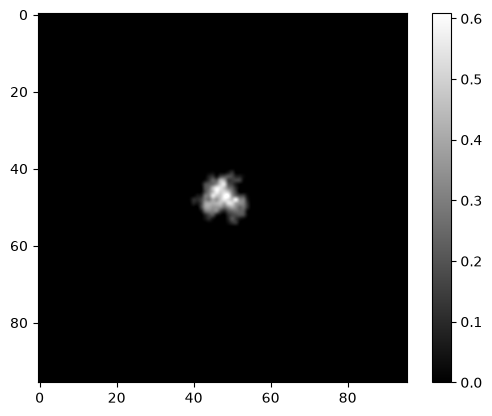

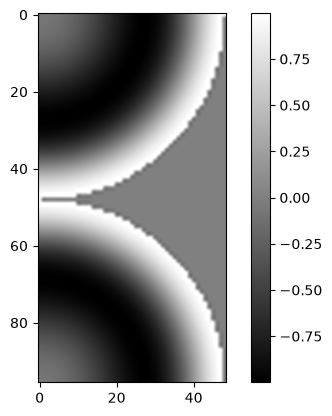

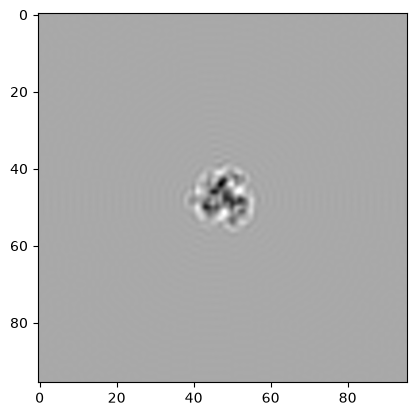

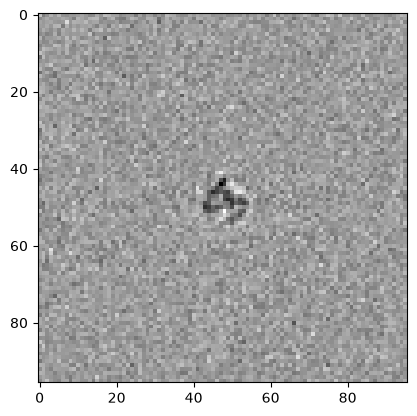

In [82]:
protein = cohesin
# protein = ribosome

# projection = ribosome.mean(dim=0) -> fourier slice teamtomo
phase = protein.mean(dim=0)
convolved = torch.fft.irfftn(torch.fft.rfftn(phase) * ctf_image, s=(BOX, BOX))

# # use a mask to find the signal only in the region with density -> exclude empty background for SNR
# # mask = projection > 0.05 * projection.max()
mask = phase > 0.05 * phase.max()

contrast = 2 * torch.fft.irfftn(torch.fft.rfftn(phase) * ctf_image, s=(BOX, BOX))  # weak-phase: I = 1 + 2·(CTF ⊛ φ)\n"

signal_var = convolved[mask].var()
# # the SNR for SPA is much higher because of the high exposure for the 2d projection ~35 e-/A^2
spa_noise_std = (signal_var / SNR_SPA).sqrt()
noisy = convolved + torch.randn_like(convolved) * spa_noise_std

plt.imshow(phase, cmap='gray', interpolation='spline16')
plt.colorbar()
plt.show()
plt.imshow(ctf_image, cmap='gray', interpolation='spline16')
plt.colorbar()
plt.show()
plt.imshow(contrast, cmap='gray', interpolation='spline16')
plt.show()
plt.imshow(noisy, cmap='gray', interpolation='nearest')
plt.show()

In [29]:
# ### Load the two proteins

# path = "C:\\Users\\ruben\\OneDrive - Delft University of Technology\\Documenten\\Nanobiology 6\\ARP\\protein_files"

# ## Ribosomes - emd_2938
# with mrcfile.open(f"{path}/emd_2938.map.gz", permissive=True) as mrc: 
#     vol_rib = mrc.data.astype(np.float32).copy() # shape (z, y, x) 
#     voxel_rib = mrc.voxel_size # Å per voxel, per axis 
#     origin_rib = mrc.header.origin

# ## Cohesin - emd_52297
# with mrcfile.open(f"{path}/emd_52297.map.gz", permissive=True) as mrc: 
#     vol_coh = mrc.data.astype(np.float32).copy() # shape (z, y, x) 
#     voxel_coh = mrc.voxel_size # Å per voxel, per axis 
#     origin_coh = mrc.header.origin

In [30]:
# print(f"The dim of ribosomes are {vol_rib.shape}, with voxelsize {voxel_rib}, origin at {origin_rib}")
# print(f"That means that ribosome takes {np.array(vol_rib.shape)*max(voxel_rib.tolist())/pixel_size} pixels")
# print(f"The dim of cohesin are {vol_coh.shape}, with voxelsize {voxel_coh}, origin at {origin_coh}")
# print(f"That means that cohesin takes {np.array(vol_coh.shape)*max(voxel_coh.tolist())/pixel_size} pixels")

## Place particles within phantom tomogram

In [4]:
from random import seed


def place_particles_spherical(mask, n, exclusion_radius, margin=0, seed=None, reserve_radius=None):
    """
    Randomly place up to n particle centers on voxels where mask == 1.
    Centers are returned in the input array's axis order.

    exclusion_radius controls spacing within this placement group. If
    reserve_radius is provided, the returned mask excludes that distance
    around each new center, for placement of another particle group.
    """
    rng = np.random.default_rng(seed)
    free = mask.astype(bool, copy=True)
    shape = free.shape

    if margin > 0:
        free[:margin] = free[-margin:] = False
        free[:, :margin] = free[:, -margin:] = False
        free[:, :, :margin] = free[:, :, -margin:] = False

    r = int(np.ceil(exclusion_radius))
    zz, yy, xx = np.ogrid[-r:r + 1, -r:r + 1, -r:r + 1]
    ball = (zz**2 + yy**2 + xx**2) <= exclusion_radius**2

    centers = []
    for _ in range(n):
        idx = np.flatnonzero(free)
        if idx.size == 0:
            print(f"No free positions left after {len(centers)} particles")
            break

        center = np.unravel_index(rng.choice(idx), shape)
        centers.append(center)

        lo = [max(ci - r, 0) for ci in center]
        hi = [min(ci + r + 1, size) for ci, size in zip(center, shape)]
        blo = [low - (ci - r) for low, ci in zip(lo, center)]
        bhi = [start + (high - low) for start, high, low in zip(blo, hi, lo)]

        free[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]] &= ~ball[
            blo[0]:bhi[0], blo[1]:bhi[1], blo[2]:bhi[2]
        ]

    if reserve_radius is None:
        next_free = free
    else:
        next_free = mask.astype(bool, copy=True)
        reserve_r = int(np.ceil(reserve_radius))
        zz, yy, xx = np.ogrid[-reserve_r:reserve_r + 1, -reserve_r:reserve_r + 1, -reserve_r:reserve_r + 1]
        reserve_ball = (zz**2 + yy**2 + xx**2) <= reserve_radius**2

        for center in centers:
            lo = [max(ci - reserve_r, 0) for ci in center]
            hi = [min(ci + reserve_r + 1, size) for ci, size in zip(center, shape)]
            blo = [low - (ci - reserve_r) for low, ci in zip(lo, center)]
            bhi = [start + (high - low) for start, high, low in zip(blo, hi, lo)]

            next_free[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]] &= ~reserve_ball[
                blo[0]:bhi[0], blo[1]:bhi[1], blo[2]:bhi[2]
            ]

    return np.array(centers, dtype=int).reshape(-1, 3), next_free

def place_particles_proteinspace(mask, shape, n, seed=None, threshold=0.05,
                                n_rotations=20, n_positions=200):
    """Place randomly rotated binary particles in free voxels of `mask`.
    Returns (centers, rotation_matrices, updated_free_mask)."""
    from scipy.ndimage import affine_transform

    free = np.asarray(mask).astype(bool, copy=True)
    particle = np.asarray(shape) >= threshold
    if not particle.any():
        raise ValueError("particle contains no voxels above threshold")

    # crop to the occupied bounding box -> much cheaper rotations
    nz = np.argwhere(particle)
    particle = particle[tuple(slice(a, b + 1) for a, b in zip(nz.min(0), nz.max(0)))]

    rng = np.random.default_rng(seed)
    vol_shape = np.array(free.shape)
    p_center = (np.array(particle.shape) - 1) / 2
    corners = np.array(np.meshgrid(*[(0, s - 1) for s in particle.shape],
                                indexing="ij")).reshape(3, -1).T - p_center

    centers, rotations = [], []
    for i in range(n):
        placed = False
        for _ in range(n_rotations):                      # new orientation if stuck
            rot = Rotation.random(random_state=rng)
            rc = rot.apply(corners)
            rmin = np.floor(rc.min(0)).astype(int)
            rshape = tuple(np.ceil(rc.max(0)).astype(int) - rmin + 1)
            inv = rot.as_matrix().T
            rotated = affine_transform(particle.astype(np.uint8), inv,
                                    offset=p_center + inv @ rmin,
                                    output_shape=rshape, order=0,
                                    prefilter=False).astype(bool)

            offsets = np.argwhere(rotated) + rmin         # voxel offsets w.r.t. center
            lo = -offsets.min(0)                          # valid center range so the
            hi = vol_shape - offsets.max(0)               # particle stays inside
            if np.any(hi <= lo):
                continue                                  # doesn't fit in this orientation

            for _ in range(n_positions):
                center = rng.integers(lo, hi)
                idx = tuple((offsets + center).T)
                if free[idx].all():
                    free[idx] = False
                    centers.append(center)
                    rotations.append(rot.as_matrix())
                    placed = True
                    break
            if placed:
                break

        if not placed:
            print(f"Placed {len(centers)}/{n}; no fit found for particle {i + 1}")
            break
        print(f"Placed {len(centers)}/{n} particles")

    return (np.asarray(centers, int).reshape(-1, 3),
            np.asarray(rotations, float).reshape(-1, 3, 3),
            free)


In [84]:
### Define the places + orientations where proteins will be inserted + z-slice
n_proteins = 200
distribution = 0.9
n_rib = round(n_proteins * distribution)
n_coh = n_proteins - n_rib
protein = ribosome
rib_centers, rib_rotations, rib_mask = place_particles_proteinspace(mask=phantom_tomo, shape=protein.numpy(), n=n_rib, seed=42)
coh_centers, coh_rotations, coh_mask = place_particles_proteinspace(mask=rib_mask, shape=cohesin.numpy(), n=n_coh, seed=42)

plot = False
if plot:
    def plot_particle_slice(z_slice):
        fig, ax = plt.subplots(figsize=(8, 8))
        image = ax.imshow(
            coh_mask[:, :, z_slice].T,
            cmap="gray",
            origin="lower",
            extent=(0, x, 0, y),
            interpolation="nearest",
            vmin=0,
            vmax=max(float(np.max(coh_mask)), 1e-12),
        )
        ax.set_aspect("equal")
        ax.set_xlabel("X (voxels)")
        ax.set_ylabel("Y (voxels)")
        ax.set_title(f"Tomogram at Z = {z_slice}")
        fig.colorbar(image, ax=ax, label="Density")

        # rib_slice = c_rib[c_rib[:, 2] == z_slice]
        # coh_slice = c_coh[c_coh[:, 2] == z_slice]
        # if len(rib_slice):
        #     ax.scatter(rib_slice[:, 0] + 0.5, rib_slice[:, 1] + 0.5, c="cyan", marker="o", label="Ribosome")
        # if len(coh_slice):
        #     ax.scatter(coh_slice[:, 0] + 0.5, coh_slice[:, 1] + 0.5, c="red", marker="x", label="Cohesin")
        # if len(rib_slice) or len(coh_slice):
        #     ax.legend()
        plt.show()


    widgets.interact(
        plot_particle_slice,
        z_slice=widgets.IntSlider(
            value=coh_mask.shape[2] // 2,
            min=0,
            max=coh_mask.shape[2] - 1,
            step=1,
            description="Z slice",
            continuous_update=False,
        ),
    );

Placed 1/180 particles
Placed 2/180 particles
Placed 3/180 particles
Placed 4/180 particles
Placed 5/180 particles
Placed 6/180 particles
Placed 7/180 particles
Placed 8/180 particles
Placed 9/180 particles
Placed 10/180 particles
Placed 11/180 particles
Placed 12/180 particles
Placed 13/180 particles
Placed 14/180 particles
Placed 15/180 particles
Placed 16/180 particles
Placed 17/180 particles
Placed 18/180 particles
Placed 19/180 particles
Placed 20/180 particles
Placed 21/180 particles
Placed 22/180 particles
Placed 23/180 particles
Placed 24/180 particles
Placed 25/180 particles
Placed 26/180 particles
Placed 27/180 particles
Placed 28/180 particles
Placed 29/180 particles
Placed 30/180 particles
Placed 31/180 particles
Placed 32/180 particles
Placed 33/180 particles
Placed 34/180 particles
Placed 35/180 particles
Placed 36/180 particles
Placed 37/180 particles
Placed 38/180 particles
Placed 39/180 particles
Placed 40/180 particles
Placed 41/180 particles
Placed 42/180 particles
P

## Store protein data

In [85]:

# protein["protein_name"] = 
df_rib = {"protein_name": np.repeat(["ribosome"], len(rib_centers)),
      "loc": rib_centers.tolist(),
      "rotation": rib_rotations.tolist()}
df_coh = {"protein_name": np.repeat(["cohesin"], len(coh_centers)),
      "loc": coh_centers.tolist(),
      "rotation": coh_rotations.tolist()}

protein_data_rib = pd.DataFrame(data=df_rib, index=np.arange(0, len(rib_centers)))
protein_data_coh = pd.DataFrame(data=df_coh, index=np.arange(len(rib_centers), len(rib_centers)+len(coh_centers)))
protein_data = pd.concat([protein_data_rib, protein_data_coh])

protein_data

,protein_name,loc,rotation
0,ribosome,"[115, 66, 50]","[[-0.25444839771337, -0.780051902626215, -0.57..."
1,ribosome,"[484, 255, 38]","[[0.7624317733851149, -0.12971571406247534, 0...."
2,ribosome,"[229, 122, 22]","[[-0.21515130693891832, -0.45329948940450454, ..."
3,ribosome,"[282, 352, 41]","[[0.10386773386587342, -0.9857175383408366, -0..."
4,ribosome,"[191, 236, 50]","[[0.7728917583152333, -0.37213218292398104, -0..."
...,...,...,...
195,cohesin,"[386, 486, 29]","[[-0.00026935239188288773, 0.2921706270616366,..."
196,cohesin,"[392, 228, 82]","[[0.22565799518860302, -0.7488210523011007, 0...."
197,cohesin,"[223, 163, 61]","[[-0.6123828156233512, -0.7902216323820435, -0..."
198,cohesin,"[400, 29, 25]","[[0.40322137350730464, -0.10797961156246015, -..."


## Insert proteins into phantom tomogram

In [5]:
### Add each protein to the empty phantom_tomo
from scipy.ndimage import affine_transform, zoom
from scipy.spatial.transform import Rotation as R

rng = np.random.default_rng(42)

from scipy.ndimage import affine_transform

def insert_particles(tomo, density, centers, rotations, threshold=0.05, pad=3, order=1):
    """Add rotated copies of `density` into `tomo` at the positions returned by
    place_particles_proteinspace (same crop, same rotation convention, same centre)."""
    density = np.asarray(density, dtype=np.float32)

    # same bounding-box crop as in the placement function ...
    nz = np.argwhere(density >= threshold)
    crop = density[tuple(slice(a, b + 1) for a, b in zip(nz.min(0), nz.max(0)))]
    # ... plus symmetric zero padding so the low-density tails aren't cut off
    # (symmetric padding keeps the crop centre in the same place)
    crop = np.pad(crop, pad)

    p_center = (np.array(crop.shape) - 1) / 2
    corners = np.array(np.meshgrid(*[(0, s - 1) for s in crop.shape],
                                indexing="ij")).reshape(3, -1).T - p_center
    vol_shape = np.array(tomo.shape)

    for center, R_mat in zip(centers, rotations):
        rot = Rotation.from_matrix(R_mat)
        rc = rot.apply(corners)
        rmin = np.floor(rc.min(0)).astype(int)
        rshape = np.ceil(rc.max(0)).astype(int) - rmin + 1
        inv = R_mat.T
        rotated = affine_transform(crop, inv, offset=p_center + inv @ rmin,
                                output_shape=tuple(rshape), order=order,
                                mode="constant", cval=0.0)

        # paste with clipping at the tomogram edges
        start = np.asarray(center) + rmin
        stop = start + rshape
        t_lo, t_hi = np.maximum(start, 0), np.minimum(stop, vol_shape)
        s_lo = t_lo - start
        s_hi = s_lo + (t_hi - t_lo)
        tomo[t_lo[0]:t_hi[0], t_lo[1]:t_hi[1], t_lo[2]:t_hi[2]] += \
            rotated[s_lo[0]:s_hi[0], s_lo[1]:s_hi[1], s_lo[2]:s_hi[2]]
    return tomo

# rib_tomo = insert_particles(phantom_tomo, ribosome.numpy(), rib_centers, rib_rotations)
# protein_tomo = insert_particles(rib_tomo, cohesin.numpy(), coh_centers, coh_rotations) 
# protein_tomo = protein_tomo / protein_tomo.max()  # normalize to [0, 1]
# # for center in c_coh:
# #     rotated_coh = rotate_volume_random(vol_coh, order=1, rng=rng)
# #     resized_coh = resize_protein_volume(rotated_coh, coh_target_size)
# #     add_volume_at_center(phantom_tomo, resized_coh, center)

# print(f"Inserted {len(rib_centers)} ribosomes and {len(coh_centers)} cohesin proteins")

In [ ]:
def plot_particle_slice(z_slice):
    fig, ax = plt.subplots(figsize=(8, 8))
    image = ax.imshow(
        protein_tomo[:, :, z_slice].T,
        cmap="gray",
        origin="lower",
        extent=(0, x, 0, y),
        interpolation="nearest",
        vmin=0,
        vmax=max(float(np.max(protein_tomo)), 1e-12),
    )
    ax.set_aspect("equal")
    ax.set_xlabel("X (voxels)")
    ax.set_ylabel("Y (voxels)")
    ax.set_title(f"Tomogram at Z = {z_slice}")
    fig.colorbar(image, ax=ax, label="Density")

    # rib_slice = c_rib[c_rib[:, 2] == z_slice]
    # coh_slice = c_coh[c_coh[:, 2] == z_slice]
    # if len(rib_slice):
    #     ax.scatter(rib_slice[:, 0] + 0.5, rib_slice[:, 1] + 0.5, c="cyan", marker="o", label="Ribosome")
    # if len(coh_slice):
    #     ax.scatter(coh_slice[:, 0] + 0.5, coh_slice[:, 1] + 0.5, c="red", marker="x", label="Cohesin")
    # if len(rib_slice) or len(coh_slice):
    #     ax.legend()
    plt.show()


widgets.interact(
    plot_particle_slice,
    z_slice=widgets.IntSlider(
        value=protein_tomo.shape[2] // 2,
        min=0,
        max=protein_tomo.shape[2] - 1,
        step=1,
        description="Z slice",
        continuous_update=False,
    ),
);

interactive(children=(IntSlider(value=50, continuous_update=False, description='Z slice', max=99), Output()), …

## For memory reasons, split tomograms into n subtomograms

In [17]:
# Make cubic with volume in the center of the cube, so that the Fourier slice theorem can be applied
x, y, z = protein_tomo.shape
n_tomo = 2 # split the tomogram into n_tomo**2 sub-tomograms to reduce memory usage
subtomo = []
subtomos = np.array_split(protein_tomo, n_tomo, axis=0) 
for protein_subtomo in subtomos:
    sub_sub_tomo = np.array_split(protein_subtomo, n_tomo, axis=1)
    subtomo.extend(sub_sub_tomo)

# reshape to z, y, x
for i, protein_subtomo in enumerate(subtomo):
    sub_x, sub_y, sub_z = protein_subtomo.shape
    # protein_subtomo_cubic = np.pad(protein_subtomo, ((0, 0), (0, 0), ((sub_x - sub_z)//2, (sub_x - sub_z)//2)), mode="constant", constant_values=0)
    subtomo[i] = np.transpose(protein_subtomo, (2, 1, 0))

x, y, z = protein_tomo.shape
full_protein_tomo_cubic = np.pad(protein_tomo, ((0, 0), (0, 0), ((x - z)//2, (x - z)//2)), mode="constant", constant_values=0)
print(full_protein_tomo_cubic.shape)

(512, 512, 512)


In [15]:
import os
os.makedirs("no_noise", exist_ok=True)
for n in range(len(subtomo)):
    with mrcfile.new(f"no_noise/no_noise_phantom_tomo_id{n}.mrc", overwrite=True) as mrc:
        mrc.set_data(subtomo[n].astype(np.float32))

## Add subtomo coordinates of proteins

In [15]:
split_x, split_y, split_z = np.array([x, y, z])//2

sub_tomo_id = []
sub_loc = []
for i, loc in enumerate(protein_data["loc"]):
    px, py, pz = loc[0], loc[1], loc[2]

    if loc[0] > split_x:
        if loc[1] > split_y:
            sub_tomo_id.append(3)
            # origin = split_x, split_y
            sub_loc.append([px - split_x, py - split_y, pz])
        else:
            sub_tomo_id.append(2)
            # origin = split_x, 0
            sub_loc.append([px - split_x, py, pz])
    else:
        if loc[1] > split_y:
            sub_tomo_id.append(1)
            # origin = 0, split_y
            sub_loc.append([px, py - split_y, pz])
        else:
            sub_tomo_id.append(0)
            # origin = 0, 0
            sub_loc.append([px, py, pz])

protein_data["subtomo_id"] = sub_tomo_id
protein_data["sub_loc"] = sub_loc

path = Path(r"C:\Users\ruben\OneDrive - Delft University of Technology\Documenten\Nanobiology 6\ARP\phantom_tomogram_29_10")
pd.DataFrame.to_csv(protein_data, path / "protein_data.csv", index=False)

## Tilt-series simulation

In [ ]:
import os

# create even and odd folders to store the half-maps
os.makedirs("even", exist_ok=True)
os.makedirs("odd", exist_ok=True)

for n in range(len(subtomo)):
    current_tomo = torch.as_tensor(subtomo[n], dtype=torch.float32)
    
    m_projection = Ry(TILT_ANGLES)[..., :3, :3]
    print("running projection")
    current_z, current_y, current_x = current_tomo.shape
    current_tomo_cubic = torch.as_tensor(np.pad(current_tomo, (((current_x - current_z)//2, (current_x - current_z)//2), (0, 0), (0, 0)), mode="constant", constant_values=0))
    tilt_series = project_3d_to_2d(current_tomo_cubic, m_projection)
    print("adding ctf per tilt")

    image_shape = tuple(tilt_series.shape[-2:])
    ctf_values_subtomo = {**ctf_values, "image_shape": image_shape}
    ctf_image_subtomo = -calculate_ctf_2d(**ctf_values_subtomo)
    frequency_grid_subtomo = fftfreq_grid(
        image_shape=image_shape, rfft=True, fftshift=False, norm=True
    )
    ctf_image_subtomo[frequency_grid_subtomo > 0.5] = 0
    ctf_per_tilt_subtomo = dose_weight_2d(
        image_dft=torch.abs(ctf_image_subtomo).repeat(len(DOSE), 1, 1),
        image_shape=image_shape,
        pixel_size=PIXEL_SPACING,
        dose=dose_per_tilt,
        voltage=VOLTAGE,
    )
    ctf_per_tilt_subtomo *= torch.cos(torch.deg2rad(TILT_ANGLES))[:, None, None]
    tilt_series_ctf = torch.fft.irfftn(
        torch.fft.rfftn(tilt_series, dim=(-2, -1)) * ctf_per_tilt_subtomo,
        dim=(-2, -1),
        s=image_shape,
    )

    # use a mask to find the signal only in the ~0 degrees tilt
    print("adding noise")
    zero_tilt_idx = len(TILT_ANGLES) // 2
    mask = tilt_series[zero_tilt_idx] > 0.05 * m_projection.max()
    signal_var = tilt_series_ctf[zero_tilt_idx][mask].var()
    # the SNR for SPA is much higher because of the high exposure for the 2d projection ~35 e-/A^2
    cet_noise_std = (signal_var / SNR_CET).sqrt()
    # tilt_series_noisy = tilt_series_ctf + torch.randn_like(tilt_series_ctf) * cet_noise_std

    # # reconstruct to a (sub-)tomogram
    # reconstruction = backproject_2d_to_3d(tilt_series_noisy, m_projection, pad_factor=2.0)
    # reconstruction_original_shape = reconstruction[..., (sub_x - sub_z)//2:-(sub_x - sub_z)//2]

    for half_map in ["even", "odd"]:

        half_noise = cet_noise_std * 2**0.5

        tilt_series_halfmap_noise = tilt_series_ctf + torch.randn_like(tilt_series_ctf) * half_noise
        reconstruction_halfmap = backproject_2d_to_3d(tilt_series_halfmap_noise, m_projection, pad_factor=2.0)
        reconstruction_halfmap_original_shape = reconstruction_halfmap[(sub_x - sub_z)//2:-(sub_x - sub_z)//2, :, :]
        
        
        with mrcfile.new(f"{half_map}/noisy_phantom_tomo_id{n}_{half_map}.mrc", overwrite=False) as mrc:
            mrc.set_data(np.array(reconstruction_halfmap_original_shape, dtype=np.float32))


# reconstruction_clean = reconstruction

# reconstruction_even_original_shape = reconstruction_even[..., (sub_x - sub_z)//2:-(sub_x - sub_z)//2]
# reconstruction_odd_original_shape = reconstruction_odd[..., (sub_x - sub_z)//2:-(sub_x - sub_z)//2]
# reconstruction_original_shape = reconstruction_clean[..., (sub_x - sub_z)//2:-(sub_x - sub_z)//2]

running projection
adding ctf per tilt
adding noise


C:\Users\ruben\AppData\Local\Temp\ipykernel_10304\2444754439.py:61: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  mrc.set_data(np.array(reconstruction_halfmap_original_shape, dtype=np.float32))


running projection
adding ctf per tilt
adding noise
running projection
adding ctf per tilt
adding noise
running projection
adding ctf per tilt
adding noise


In [23]:
import napari
viewer = napari.Viewer()
viewer.add_image(mrcfile.read(r'C:\Users\ruben\OneDrive - Delft University of Technology\Documenten\Nanobiology 6\ARP\phantom_tomogram_29_10/even/noisy_phantom_tomo_id0_even.mrc'))

<Image layer 'Image' at 0x1c2603892b0>

In [24]:
mrcfile.read('phantom_tomogram_13_10/even/noisy_phantom_tomo_id0_even.mrc').shape

FileNotFoundError: [Errno 2] No such file or directory: 'phantom_tomogram_13_10/even/noisy_phantom_tomo_id0_even.mrc'

## Create half-maps based on dose

In [26]:
half_noise = cet_noise_std * 2**0.5

tilt_series_even = tilt_series_ctf + torch.randn_like(tilt_series_ctf) * half_noise
tilt_series_odd = tilt_series_ctf + torch.randn_like(tilt_series_ctf) * half_noise

reconstruction_even = backproject_2d_to_3d(tilt_series_even, m_projection, pad_factor=2.0)
reconstruction_odd = backproject_2d_to_3d(tilt_series_odd, m_projection, pad_factor=2.0)

reconstruction_clean = (reconstruction_even + reconstruction_odd) / 2

reconstruction_even_original_shape = reconstruction_even[..., (sub_x - sub_z)//2:-(sub_x - sub_z)//2]
reconstruction_odd_original_shape = reconstruction_odd[..., (sub_x - sub_z)//2:-(sub_x - sub_z)//2]
reconstruction_original_shape = reconstruction_clean[..., (sub_x - sub_z)//2:-(sub_x - sub_z)//2]

In [27]:
viewer = napari.Viewer()
viewer.add_image(reconstruction_even_original_shape.numpy(), name="even")
viewer.add_image(reconstruction_odd_original_shape.numpy(), name="odd")
viewer.add_image(reconstruction_original_shape.numpy(), name="clean")

<Image layer 'clean' at 0x1c261dcdf90>

In [29]:
import mrcfile, numpy as np, re
from pathlib import Path

ROOT = Path(r"C:\Users\ruben\OneDrive - Delft University of Technology\Documenten\Nanobiology 6\ARP\phantom_tomogram_29_10")
FOLDERS = ["even", "odd", "no_noise", "noise_subtomo"]
EXPECTED_SHAPE = (256, 256, 100)   # after cropping; set to (256, 256, 256) to check the current padded files
EXPECTED_IDS = {0, 1, 2, 3}

def padding_per_axis(vol, tol=1e-8):
    """Number of all-zero slices at the start/end of each axis -> detects zero padding."""
    out = []
    for ax in range(vol.ndim):
        other = tuple(a for a in range(vol.ndim) if a != ax)
        nonzero = np.abs(vol).max(axis=other) > tol
        idx = np.flatnonzero(nonzero)
        out.append((0, 0) if idx.size == 0 else (int(idx[0]), int(vol.shape[ax] - 1 - idx[-1])))
    return out

problems, shapes_by_id = [], {}
for folder in FOLDERS:
    files = sorted((ROOT / folder).glob("*.mrc"))
    print(f"\n=== {folder}/  ({len(files)} files) ===")
    if not files:
        problems.append(f"{folder}: no .mrc files")
        continue
    ids = set()
    for f in files:
        m_id = re.search(r"id(\d+)", f.name)
        tid = int(m_id.group(1)) if m_id else None
        ids.add(tid)
        with mrcfile.open(f, permissive=True) as m:
            vol = np.asarray(m.data, dtype=np.float32)
            vs = tuple(round(float(v), 3) for v in (m.voxel_size.x, m.voxel_size.y, m.voxel_size.z))
        pad = padding_per_axis(vol)
        print(f"{f.name:45s} shape={vol.shape}  voxel={vs}  dtype={vol.dtype}  "
              f"min={vol.min():.3g} max={vol.max():.3g} mean={vol.mean():.3g} std={vol.std():.3g}")
        print(f"{'':45s} zero-padding per axis (start, end): {pad}")
        shapes_by_id.setdefault(tid, {})[folder] = vol.shape
        if vol.shape != EXPECTED_SHAPE:
            problems.append(f"{folder}/{f.name}: shape {vol.shape} != expected {EXPECTED_SHAPE}")
        if any(p != (0, 0) for p in pad) and folder != "no_noise":
            problems.append(f"{folder}/{f.name}: still contains zero padding {pad}")
        if not np.isfinite(vol).all():
            problems.append(f"{folder}/{f.name}: contains NaN/inf")
        if vs == (0.0, 0.0, 0.0) or vs == (1.0, 1.0, 1.0):
            problems.append(f"{folder}/{f.name}: voxel size not set ({vs}); expected 10 Å")
    missing = EXPECTED_IDS - ids
    if missing and folder in ("even", "odd", "no_noise"):
        problems.append(f"{folder}: missing ids {sorted(missing)}")

print("\n=== Consistency across folders per tomogram id ===")
for tid, d in sorted(shapes_by_id.items(), key=lambda kv: (kv[0] is None, kv[0])):
    same = len(set(d.values())) == 1
    print(f"id{tid}: {d}  {'OK' if same else 'MISMATCH'}")
    if not same:
        problems.append(f"id{tid}: shapes differ across folders {d}")

# Missing-wedge orientation: fraction of (near-)empty Fourier coefficients in each central plane.
# The plane containing the beam axis shows ~ wedge/180 empty (72/180 = 40% for ±54°); the other planes ~0%.
print("\n=== Missing-wedge check (even/, first file) ===")
f0 = sorted((ROOT / "even").glob("*.mrc"))[0]
with mrcfile.open(f0, permissive=True) as m:
    vol = np.asarray(m.data, dtype=np.float32)
F = np.abs(np.fft.fftshift(np.fft.fftn(vol - vol.mean())))
c = [s // 2 for s in F.shape]
planes = {"axes (1,2) [slice axis 0]": F[c[0], :, :],
          "axes (0,2) [slice axis 1]": F[:, c[1], :],
          "axes (0,1) [slice axis 2]": F[:, :, c[2]]}
for name, P in planes.items():
    thr = 1e-3 * np.median(P[P > 0]) if (P > 0).any() else 0
    print(f"central plane {name}: {100 * (P <= thr).mean():5.1f}% empty")
print("-> The plane with ~40% empty contains the beam axis and the axis perpendicular to the tilt axis.\n"
      "   The axis you slice along there is the tilt axis. For ICECREAM/DeepDeWedge (mrc order z,y,x) the tilt axis should be y\n"
      "   (axis 1) and the beam z (axis 0) -> expected: 'slice axis 1' ~40% empty.")

print("\n=== SUMMARY ===")
print("No problems found." if not problems else "\n".join("• " + p for p in problems))


=== even/  (4 files) ===
noisy_phantom_tomo_id0_even.mrc               shape=(100, 256, 256)  voxel=(0.0, 0.0, 0.0)  dtype=float32  min=-0.0209 max=0.0292 mean=0.000131 std=0.00407
                                              zero-padding per axis (start, end): [(0, 0), (0, 0), (0, 0)]
noisy_phantom_tomo_id1_even.mrc               shape=(100, 256, 256)  voxel=(0.0, 0.0, 0.0)  dtype=float32  min=-0.0206 max=0.0261 mean=0.000106 std=0.00389
                                              zero-padding per axis (start, end): [(0, 0), (0, 0), (0, 0)]
noisy_phantom_tomo_id2_even.mrc               shape=(100, 256, 256)  voxel=(0.0, 0.0, 0.0)  dtype=float32  min=-0.0247 max=0.0325 mean=0.000128 std=0.00443
                                              zero-padding per axis (start, end): [(0, 0), (0, 0), (0, 0)]
noisy_phantom_tomo_id3_even.mrc               shape=(100, 256, 256)  voxel=(0.0, 0.0, 0.0)  dtype=float32  min=-0.0247 max=0.0283 mean=9.15e-05 std=0.00418
                             

In [30]:
import mrcfile, numpy as np, napari
from pathlib import Path

ROOT = Path(r"C:\Users\ruben\OneDrive - Delft University of Technology\Documenten\Nanobiology 6\ARP\phantom_tomogram_29_10")
TID = 0  # which tomogram id to inspect

files = {
    "even":     ROOT / "even"     / f"noisy_phantom_tomo_id{TID}_even.mrc",
    "odd":      ROOT / "odd"      / f"noisy_phantom_tomo_id{TID}_odd.mrc",
    "no_noise": ROOT / "no_noise" / f"no_noise_phantom_tomo_id{TID}.mrc",
}

vols = {}
for name, f in files.items():
    with mrcfile.open(f, permissive=True) as m:
        vols[name] = np.asarray(m.data, dtype=np.float32).copy()
    print(f"{name:9s} {vols[name].shape}")

# --- Determine the crop from the clean volume (padding = exactly zero there) ---
clean = vols["no_noise"]
crop = []
for ax in range(3):
    other = tuple(a for a in range(3) if a != ax)
    idx = np.flatnonzero(np.abs(clean).max(axis=other) > 0)
    lo, hi = int(idx[0]), int(idx[-1]) + 1
    crop.append((lo, hi))
    print(f"axis {ax}: signal in [{lo}, {hi})  -> {hi - lo} voxels, "
          f"padding {lo} at start / {clean.shape[ax] - hi} at end")
crop_slices = tuple(slice(lo, hi) for lo, hi in crop)
print("Suggested crop (apply to even/odd/no_noise):", crop_slices)

# --- Fourier space: log-magnitude, centred ---
def log_fft(v):
    F = np.fft.fftshift(np.fft.fftn(v - v.mean()))
    return np.log1p(np.abs(F)).astype(np.float32)

ffts = {name: log_fft(v) for name, v in vols.items()}

def clim(v, lo=1, hi=99.5):
    return tuple(np.percentile(v, [lo, hi]).tolist())

# --- Viewer 1: real space (side by side via grid) ---
v_real = napari.Viewer(title=f"Real space – id{TID}")
for name, v in vols.items():
    v_real.add_image(v, name=name, colormap="gray", contrast_limits=clim(v))
v_real.add_image(vols["even"][crop_slices], name="even (cropped)", colormap="gray",
                 contrast_limits=clim(vols["even"][crop_slices]))
v_real.grid.enabled = True
v_real.dims.axis_labels = ("axis0", "axis1", "axis2")

# --- Viewer 2: Fourier space ---
v_fft = napari.Viewer(title=f"Fourier space (log|F|) – id{TID}")
for name, F in ffts.items():
    v_fft.add_image(F, name=f"FFT {name}", colormap="magma", contrast_limits=clim(F, 5, 99.9))
v_fft.grid.enabled = True
v_fft.dims.axis_labels = ("kz/axis0", "ky/axis1", "kx/axis2")
# jump to the central slice so you see the plane through the origin
v_fft.dims.current_step = tuple(s // 2 for s in ffts["even"].shape)

napari.run()

even      (100, 256, 256)
odd       (100, 256, 256)
no_noise  (100, 256, 256)
axis 0: signal in [0, 100)  -> 100 voxels, padding 0 at start / 0 at end
axis 1: signal in [1, 256)  -> 255 voxels, padding 1 at start / 0 at end
axis 2: signal in [0, 256)  -> 256 voxels, padding 0 at start / 0 at end
Suggested crop (apply to even/odd/no_noise): (slice(0, 100, None), slice(1, 256, None), slice(0, 256, None))


## Untrained protein complexes analysis

In [6]:
# Drop-in replacement for simulate_pdb() in Simulation_phantom_tomogram.ipynb.
# EMD-8528 is a density map; its fitted atomic model is PDB 5UBQ
# (Tetrahymena ciliary doublet microtubule, 8 nm repeat, 5.7 A).
# 5ubq.cif only holds the asymmetric unit (3 alpha/beta dimers), so we fetch
# biological assembly 1 (69 dimers = full doublet, ~24 nm long) and can
# optionally stack it along the filament axis to make a longer piece.
import pandas as pd


def simulate_pdb(
    pdb_id: str,
    device: str = "cuda",
    assembly: int | None = None,
    repeats: int = 1,
    repeat_A: float = 240.0,
    axis: str = "z",
) -> torch.Tensor:
    """Download a PDB entry and simulate its potential in volts (cached on disk).

    assembly: download biological assembly N instead of the asymmetric unit.
    repeats:  copies of the structure stacked along `axis`, shifted by `repeat_A`.
    """
    CACHE.mkdir(parents=True, exist_ok=True)
    name = pdb_id if assembly is None else f"{pdb_id}-assembly{assembly}"
    tag = name if repeats == 1 else f"{name}_x{repeats}"
    volume_path = CACHE / f"{tag}_box{BOX}_{PIXEL_SPACING:g}apx_peng.pt"
    if volume_path.exists():
        return torch.load(volume_path)

    structure_path = CACHE / f"{name}.cif"
    if not structure_path.exists():
        print(f"downloading {name} from RCSB ...")
        response = urllib3.PoolManager().request(
            "GET", f"https://files.rcsb.org/download/{name}.cif"
        )
        if response.status != 200:
            raise RuntimeError(f"download of {name} failed: HTTP {response.status}")
        structure_path.write_bytes(response.data)

    atoms = mmdf.read(str(structure_path))
    extent = {c: float(atoms[c].max() - atoms[c].min()) for c in "xyz"}
    print(f"{name}: {len(atoms)} atoms, extent (A) {extent}")
    if repeats > 1:
        copies = []
        for k in range(repeats):
            shifted = atoms.copy()
            shifted[axis] = shifted[axis] + k * repeat_A
            copies.append(shifted)
        atoms = pd.concat(copies, ignore_index=True)

    print(f"simulating {tag}: {BOX}^3 volume at {PIXEL_SPACING} A/px ...")
    atoms = center_structure(atoms, zyx=False)
    structure = AtomicStructure.from_annotated_dataframe(atoms, device=device)
    grid_3d = GridConfig.from_grid_shape_and_voxel_size(
        grid_shape=(BOX, BOX, BOX),
        voxel_size=(PIXEL_SPACING,) * 3,
        center_zyx=(0.0, 0.0, 0.0),
        sublattice_radius=default_sublattice_radius(PIXEL_SPACING),
        device=torch.device(device),
    )
    volume = potential_from_structure_3d(
        structure, grid_3d,
        scattering_factors="peng_bonded", bonded_fallback="elemental",
    ).cpu()
    torch.save(volume, volume_path)
    return volume


## Lets first insert microtubules and proteasome 30S - Ubp complex

proteasome = simulate_pdb("5A5B", device='cpu')

PDB_ID_microtubule = "5ubq"  # fitted model of EMD-8528
# one 24 nm doublet segment (fits easily in the 960 A box)
microtubule_3 = simulate_pdb(PDB_ID_microtubule, device="cpu", assembly=1, repeats=3)
# or a 72 nm piece: 3 segments stacked along the filament axis
# microtubule = simulate_pdb(PDB_ID_microtubule, device="cpu", assembly=1, repeats=3)

In [26]:
import napari
a = napari.Viewer()
a.add_image(microtubule_3, name="microtubule")
a.add_image(proteasome, name="proteasome")

<Image layer 'proteasome' at 0x23046cb20d0>

In [7]:
def split_boundaries(length, n_split):
    """Indices where np.array_split(..., n_split) starts a new chunk along one axis."""
    sizes = [len(c) for c in np.array_split(np.arange(length), n_split)]
    return np.cumsum(sizes)[:-1]
 
 
def place_particles_proteinspace(mask, shape, n, seed=None, threshold=0.05,
                                n_rotations=20, n_positions=200,
                                Split_tomo_in_four=False, n_split=2, split_axes=(0, 1),
                                split_margin=0):
    """Place randomly rotated binary particles in free voxels of `mask`.
    If Split_tomo_in_four, no particle crosses the planes where the volume is later cut
    with np.array_split(n_split) along `split_axes` (n_split=2 -> 4 sub-tomograms),
    and particles stay `split_margin` voxels away from those planes.
    Returns (centers, rotation_matrices, updated_free_mask)."""
    from scipy.ndimage import affine_transform
 
    free = np.asarray(mask).astype(bool, copy=True)
    particle = np.asarray(shape) >= threshold
    if not particle.any():
        raise ValueError("particle contains no voxels above threshold")
 
    # crop to the occupied bounding box -> much cheaper rotations
    nz = np.argwhere(particle)
    particle = particle[tuple(slice(a, b + 1) for a, b in zip(nz.min(0), nz.max(0)))]
 
    rng = np.random.default_rng(seed)
    vol_shape = np.array(free.shape)
    p_center = (np.array(particle.shape) - 1) / 2
    corners = np.array(np.meshgrid(*[(0, s - 1) for s in particle.shape],
                                indexing="ij")).reshape(3, -1).T - p_center
 
    # same cut positions as the np.array_split used to make the sub-tomograms
    boundaries = {ax: split_boundaries(vol_shape[ax], n_split) for ax in split_axes} \
        if Split_tomo_in_four else {}
 
    def crosses_split(coords):
        for ax, bounds in boundaries.items():
            lo_c, hi_c = coords[:, ax].min(), coords[:, ax].max()
            # particle spans [lo_c, hi_c]; it must sit fully on one side of every cut,
            # with split_margin voxels of clearance
            if np.any((lo_c < bounds + split_margin) & (hi_c >= bounds - split_margin)):
                return True
        return False
 
    centers, rotations = [], []
    for i in range(n):
        placed = False
        for _ in range(n_rotations):                      # new orientation if stuck
            rot = Rotation.random(random_state=rng)
            rc = rot.apply(corners)
            rmin = np.floor(rc.min(0)).astype(int)
            rshape = tuple(np.ceil(rc.max(0)).astype(int) - rmin + 1)
            inv = rot.as_matrix().T
            rotated = affine_transform(particle.astype(np.uint8), inv,
                                    offset=p_center + inv @ rmin,
                                    output_shape=rshape, order=0,
                                    prefilter=False).astype(bool)
 
            offsets = np.argwhere(rotated) + rmin         # voxel offsets w.r.t. center
            lo = -offsets.min(0)                          # valid center range so the
            hi = vol_shape - offsets.max(0)               # particle stays inside
            if np.any(hi <= lo):
                continue                                  # doesn't fit in this orientation
 
            for _ in range(n_positions):
                center = rng.integers(lo, hi)
                coords = offsets + center
                if crosses_split(coords):
                    continue                              # would be cut by the split
                idx = tuple(coords.T)
                if free[idx].all():
                    free[idx] = False
                    centers.append(center)
                    rotations.append(rot.as_matrix())
                    placed = True
                    break
            if placed:
                break
 
        if not placed:
            print(f"Placed {len(centers)}/{n}; no fit found for particle {i + 1}")
            break
        print(f"Placed {len(centers)}/{n} particles")
 
    return (np.asarray(centers, int).reshape(-1, 3),
            np.asarray(rotations, float).reshape(-1, 3, 3),
            free)
 

In [8]:
### Define phantom volume sizes
z, y, x = 100, 512, 512 
pixel_size = 10 #Angstrom
phantom_tomo = np.ones((x, y, z))


### Define the places + orientations where proteins will be inserted + z-slice
n_proteins = 200
distribution = 0.9
n_proteasome = round(n_proteins * distribution)
n_tubulin = n_proteins - n_proteasome
protein = proteasome
protein_2 = microtubule_3
tubulin_centers, tubulin_rotations, tubulin_mask = place_particles_proteinspace(
    mask=phantom_tomo, shape=protein_2.numpy(), n=n_tubulin, seed=42, Split_tomo_in_four=True, split_margin=1
    )
proteasome_centers, proteasome_rotations, proteasome_mask = place_particles_proteinspace(
    mask=tubulin_mask, shape=protein.numpy(), n=n_proteasome, seed=42, Split_tomo_in_four=True, split_margin=1
    )


plot = False
if plot:
    def plot_particle_slice(z_slice):
        fig, ax = plt.subplots(figsize=(8, 8))
        image = ax.imshow(
            tubulin_mask[:, :, z_slice].T,
            cmap="gray",
            origin="lower",
            extent=(0, x, 0, y),
            interpolation="nearest",
            vmin=0,
            vmax=max(float(np.max(coh_mask)), 1e-12),
        )
        ax.set_aspect("equal")
        ax.set_xlabel("X (voxels)")
        ax.set_ylabel("Y (voxels)")
        ax.set_title(f"Tomogram at Z = {z_slice}")
        fig.colorbar(image, ax=ax, label="Density")

        # rib_slice = c_rib[c_rib[:, 2] == z_slice]
        # coh_slice = c_coh[c_coh[:, 2] == z_slice]
        # if len(rib_slice):
        #     ax.scatter(rib_slice[:, 0] + 0.5, rib_slice[:, 1] + 0.5, c="cyan", marker="o", label="Ribosome")
        # if len(coh_slice):
        #     ax.scatter(coh_slice[:, 0] + 0.5, coh_slice[:, 1] + 0.5, c="red", marker="x", label="Cohesin")
        # if len(rib_slice) or len(coh_slice):
        #     ax.legend()
        plt.show()


    widgets.interact(
        plot_particle_slice,
        z_slice=widgets.IntSlider(
            value=coh_mask.shape[2] // 2,
            min=0,
            max=coh_mask.shape[2] - 1,
            step=1,
            description="Z slice",
            continuous_update=False,
        ),
    );

Placed 1/20 particles
Placed 2/20 particles
Placed 3/20 particles
Placed 4/20 particles
Placed 5/20 particles
Placed 6/20 particles
Placed 7/20 particles
Placed 8/20 particles
Placed 9/20 particles
Placed 10/20 particles
Placed 11/20 particles
Placed 12/20 particles
Placed 13/20 particles
Placed 14/20 particles
Placed 15/20 particles
Placed 16/20 particles
Placed 17/20 particles
Placed 18/20 particles
Placed 19/20 particles
Placed 20/20 particles
Placed 1/180 particles
Placed 2/180 particles
Placed 3/180 particles
Placed 4/180 particles
Placed 5/180 particles
Placed 6/180 particles
Placed 7/180 particles
Placed 8/180 particles
Placed 9/180 particles
Placed 10/180 particles
Placed 11/180 particles
Placed 12/180 particles
Placed 13/180 particles
Placed 14/180 particles
Placed 15/180 particles
Placed 16/180 particles
Placed 17/180 particles
Placed 18/180 particles
Placed 19/180 particles
Placed 20/180 particles
Placed 21/180 particles
Placed 22/180 particles
Placed 23/180 particles
Placed

In [37]:
ab = napari.Viewer()
ab.add_image(np.ones((proteasome_mask.shape))-proteasome_mask)

<Image layer 'Image' at 0x23164cc9090>

In [9]:

# protein["protein_name"] = 
df_proteasome = {"protein_name": np.repeat(["proteasome"], len(proteasome_centers)),
      "loc": proteasome_centers.tolist(),
      "rotation": proteasome_rotations.tolist()}
df_tubulin = {"protein_name": np.repeat(["tubulin"], len(tubulin_centers)),
      "loc": tubulin_centers.tolist(),
      "rotation": tubulin_rotations.tolist()}

protein_data_proteasome = pd.DataFrame(data=df_proteasome, index=np.arange(0, len(proteasome_centers)))
protein_data_tubulin = pd.DataFrame(data=df_tubulin, index=np.arange(len(proteasome_centers), len(tubulin_centers)+len(proteasome_centers)))
protein_data = pd.concat([protein_data_proteasome, protein_data_tubulin])

protein_data

,protein_name,loc,rotation
0,proteasome,"[488, 371, 70]","[[-0.25444839771337, -0.780051902626215, -0.57..."
1,proteasome,"[328, 209, 72]","[[0.09079027382960775, 0.9435716083997393, 0.3..."
2,proteasome,"[429, 418, 30]","[[0.1310189688724035, -0.04784236300246619, 0...."
3,proteasome,"[321, 341, 69]","[[-0.9424165939774339, 0.31224807140937194, -0..."
4,proteasome,"[374, 345, 84]","[[-0.172311303659673, -0.9512133137362897, 0.2..."
...,...,...,...
195,tubulin,"[83, 320, 57]","[[0.86306560354846, -0.34012092582172104, -0.3..."
196,tubulin,"[43, 108, 74]","[[-0.4442239407590637, -0.8346597425247397, 0...."
197,tubulin,"[456, 176, 42]","[[0.7247857827814533, -0.6846135681922154, -0...."
198,tubulin,"[419, 70, 59]","[[0.9131299621435665, -0.28845701389065626, 0...."


Inserted 20 tubilin and 180 proteasome proteins


(array([2.5036474e+07, 8.7603000e+04, 8.1809000e+04, 7.7669000e+04,
        7.5546000e+04, 7.3828000e+04, 7.3862000e+04, 7.4684000e+04,
        7.6397000e+04, 8.0428000e+04, 8.5108000e+04, 8.9844000e+04,
        9.3829000e+04, 8.7328000e+04, 6.2152000e+04, 3.0237000e+04,
        1.2598000e+04, 5.7750000e+03, 3.2190000e+03, 2.0840000e+03,
        1.4670000e+03, 1.0030000e+03, 7.1400000e+02, 3.9000000e+02,
        1.9100000e+02, 9.0000000e+01, 4.3000000e+01, 2.0000000e+01,
        6.0000000e+00, 2.0000000e+00]),
 array([0.1 , 0.13, 0.16, 0.19, 0.22, 0.25, 0.28, 0.31, 0.34, 0.37, 0.4 ,
        0.43, 0.46, 0.49, 0.52, 0.55, 0.58, 0.61, 0.64, 0.67, 0.7 , 0.73,
        0.76, 0.79, 0.82, 0.85, 0.88, 0.91, 0.94, 0.97, 1.  ]),
 <BarContainer object of 30 artists>)

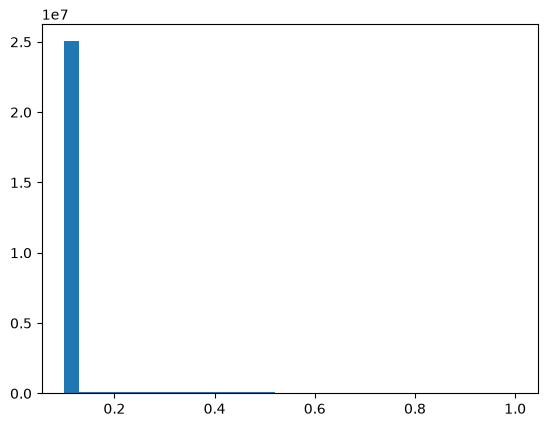

In [10]:
empty_tomo = np.zeros((phantom_tomo.shape))
tubulin_tomo = insert_particles(empty_tomo, microtubule_3.numpy(), tubulin_centers, tubulin_rotations)
final_tomo = insert_particles(tubulin_tomo, proteasome.numpy(), proteasome_centers, proteasome_rotations) 
protein_tomo = final_tomo / final_tomo.max()  # normalize to [0, 1]
# for center in c_coh:
#     rotated_coh = rotate_volume_random(vol_coh, order=1, rng=rng)
#     resized_coh = resize_protein_volume(rotated_coh, coh_target_size)
#     add_volume_at_center(phantom_tomo, resized_coh, center)

print(f"Inserted {len(tubulin_centers)} tubilin and {len(proteasome_centers)} proteasome proteins")

plt.hist(protein_tomo.flatten().clip(0.1,1), bins=30)

<Image layer 'protein_tomo' at 0x230dd918410>